## 1. Goal and evaluation setup
here we have to compare five classification models on the **same stratified 80/20 split** (random_state=42). In this notebook, malignant=1 is the positive class. The six metrics are accuracy, ROC AUC, precision, recall, F1, and MCC. Preprocessing stays inside training-only fitted pipelines to avoid test leakage.

In [1]:
from pathlib import Path
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from IPython.display import display

base = Path.cwd()
data = load_breast_cancer(as_frame=True)
X = data.data
y = (data.target == 0).astype(int)  # malignant=1, benign=0
print(f"Dataset shape: {X.shape}")
print("Class counts (0=benign, 1=malignant):")
print(y.value_counts().sort_index())
display(X.head(3))

Dataset shape: (569, 30)
Class counts (0=benign, 1=malignant):
target
0    357
1    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


## 2. Train the five models and save artifacts


In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, matthews_corrcoef

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# 1. Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 2. Define the five models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(probability=True, random_state=42)
}

# 3. Train models inside pipelines and evaluate
results = []
for name, model in models.items():
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    # Handle probability for ROC AUC if decision_function is not available
    if hasattr(pipeline, "predict_proba"):
        y_prob = pipeline.predict_proba(X_test)[:, 1]
    else:
        y_prob = pipeline.decision_function(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

# 4. Save results to CSV
comparison_df = pd.DataFrame(results)
comparison_df.to_csv(base / "model_comparison.csv", index=False)
print("Models trained and successfully saved to model_comparison.csv.")

Models trained and successfully saved to model_comparison.csv.


## 3. Inspect the comparison table

In [4]:
comparison = pd.read_csv(base / "model_comparison.csv")
display(comparison.round(4).sort_values("F1", ascending=False))

,Model,Accuracy,ROC AUC,Precision,Recall,F1,MCC
4,Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
1,Decision Tree,0.9298,0.9246,0.9048,0.9048,0.9048,0.8492
3,Naive Bayes,0.9211,0.9891,0.9231,0.8571,0.8889,0.8292


## 4. Visualize model performance

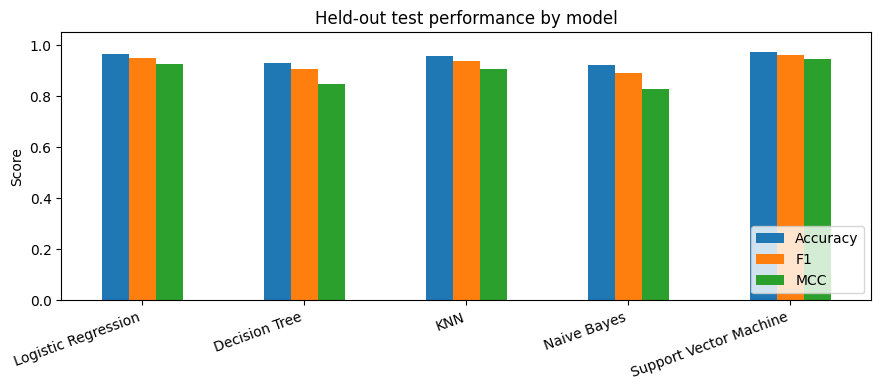

In [5]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(9,4))
comparison.plot.bar(x="Model",y=["Accuracy","F1","MCC"],ax=ax)
ax.set_title("Held-out test performance by model")
ax.set_ylim(0,1.05)
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.legend(loc="lower right")
plt.xticks(rotation=20,ha="right")
plt.tight_layout()
plt.show()